# Домашнее задание 1: персональные top-10 рекомендации

**Данные:** [Amazon Review Data 2018, Musical Instruments](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/index.html),
5-core и метаданные товаров. Исходная выборка содержит 231 392 отзыва.
Авторы: Jianmo Ni, Jiacheng Li, Julian McAuley, EMNLP 2019.

Рекомендуем ранее не оценённые товары; релевантность — будущая оценка 4 или 5.

Для воспроизведения установите зависимости из `requirements.txt`, откройте
`experiments.ipynb` в Jupyter и выполните ячейки по порядку. Данные скачиваются автоматически;
готовые архивы используются повторно. Параметры и случайные зерна заданы в коде.


In [1]:
import os
from pathlib import Path

SEED = 42
N_THREADS = 2
DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
DEVICE = "cpu"

for variable in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[variable] = str(N_THREADS)

In [2]:
import json
import random
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from data import (
    SOURCE, FILES, download_data, read_reviews, clean_reviews,
    read_metadata, encode_ids, temporal_split, make_item_features,
)
from evaluation import prepare_evaluation
from experiment import tune_models, final_comparison
from models import ItemKNN, IALS, EASE, FM, CustomIALS, Popularity

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(N_THREADS)
pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.figsize"] = (10, 4)

display(pd.Series({name: version(name) for name in ["numpy", "scipy", "pandas", "torch", "matplotlib"]}, name="version"))

numpy          2.1.2
scipy         1.15.2
pandas         2.2.3
torch          2.4.0
matplotlib    3.10.1
Name: version, dtype: object

## 1. Загрузка и смысл полей

- `user_id` (`reviewerID`) — пользователь.
- `asin` — товар, единица рекомендации.
- `rating` (`overall`) — оценка 1–5.
- `timestamp` (`unixReviewTime`) — дата отзыва, далее переводится в UTC.
- `title`, `brand`, `category` — метаданные товара; `category` — последняя категория пути.

Читаем из архивов только нужные поля. Метаданные загружаем только для товаров из выбранного 5-core.
Все оценки сохраняются, включая низкие. В GitHub сами архивы не загружаются.

In [3]:
display(pd.Series(FILES, name="download_url"))
download_data(DATA_DIR)

raw = read_reviews(DATA_DIR / "Musical_Instruments_5.json.gz")
display(raw.head())
print(f"Исходное число отзывов: {len(raw):,}")

Musical_Instruments_5.json.gz       https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/Musical_Instruments_5.json.gz
meta_Musical_Instruments.json.gz         https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/metaFiles2/meta_Musical_Instruments.json.gz
Name: download_url, dtype: object

Скачивание Musical_Instruments_5.json.gz


Скачивание meta_Musical_Instruments.json.gz


,user_id,asin,rating,timestamp
0,A3FO5AKVTFRCRJ,0739079891,5.0,1477785600
1,A3UCGC1DHFMBCE,0739079891,5.0,1467244800
2,A2S9SLRYLPGYZB,0739079891,5.0,1462752000
3,A15RTJWPG8OKOE,0739079891,4.0,1460246400
4,A12ET1WO3OAVU7,0739079891,1.0,1454716800


Исходное число отзывов: 231,392


## 2. EDA и подготовка

Сначала проверяем пропуски и повторы. Удаляем строки без ID, оценки или корректной даты,
а также оценки вне диапазона 1–5. Для повторных пар сохраняем **первый** отзыв:
поздняя оценка не должна подменять раннюю историю или становиться повторной рекомендацией.
Дополнительные k-core фильтры и случайную подвыборку не применяем.

In [4]:
display(raw.isna().sum().to_frame("missing"))
display(pd.Series({
    "full_duplicates": int(raw.duplicated().sum()),
    "repeated_user_item": int(raw.duplicated(["user_id", "asin"]).sum()),
    "invalid_ratings": int((~raw.rating.between(1, 5) & raw.rating.notna()).sum()),
}, name="rows"))

cleaned = clean_reviews(raw)
valid_rows = raw.dropna(subset=["user_id", "asin", "rating", "timestamp"])
valid_rows = valid_rows[valid_rows.rating.between(1, 5)]
valid_rows = valid_rows[pd.to_datetime(valid_rows.timestamp, unit="s", utc=True, errors="coerce").notna()]
display(pd.DataFrame({
    "step": ["raw", "valid fields", "first user-item interaction"],
    "interactions": [len(raw), len(valid_rows), len(cleaned)],
}))

data, user_ids, item_ids = encode_ids(cleaned)
shape = (len(user_ids), len(item_ids))
items = read_metadata(DATA_DIR / "meta_Musical_Instruments.json.gz", item_ids)

assert 100_000 <= len(data) <= 2_000_000, "Итоговый объём не соответствует условию ДЗ."
assert min(shape) >= 1_000, "Нужно не менее 1000 пользователей и товаров."
display(data.head())

,missing
user_id,0
asin,0
rating,0
timestamp,0


full_duplicates       10295
repeated_user_item    12236
invalid_ratings           0
Name: rows, dtype: int64

,step,interactions
0,raw,231392
1,valid fields,231392
2,first user-item interaction,219156


,user_id,asin,rating,timestamp,user,item
0,A1YC9XEDFKXPLK,B00006HO3L,4.0,2003-10-28 00:00:00+00:00,6954,43
1,A2B1OJ22IYM3NR,B00001W0DH,3.0,2004-03-27 00:00:00+00:00,9541,6
2,A17BUUBOU0598B,B00001W0DT,4.0,2004-06-01 00:00:00+00:00,1455,7
3,A17BUUBOU0598B,B00006HOLL,5.0,2004-06-01 00:00:00+00:00,1455,45
4,A2NEVXUACYIECB,B0002CZVKA,4.0,2004-07-20 00:00:00+00:00,11986,196


In [5]:
user_activity = data.groupby("user").size()
item_popularity = data.groupby("item").size()
sparsity = 1 - len(data) / (shape[0] * shape[1])

display(pd.Series({
    "raw_interactions": len(raw),
    "clean_interactions": len(data),
    "users": shape[0],
    "items": shape[1],
    "sparsity": sparsity,
    "positive_fraction": (data.rating >= 4).mean(),
    "top_1_percent_item_share": item_popularity.nlargest(max(1, shape[1] // 100)).sum() / len(data),
}, name="value"))
display(pd.DataFrame({
    "user_activity": user_activity.describe(percentiles=[0.5, 0.9, 0.99]),
    "item_popularity": item_popularity.describe(percentiles=[0.5, 0.9, 0.99]),
}))

raw_interactions            231392.000000
clean_interactions          219156.000000
users                        27530.000000
items                        10620.000000
sparsity                         0.999250
positive_fraction                0.867159
top_1_percent_item_share         0.204229
Name: value, dtype: float64

,user_activity,item_popularity
count,27530.000000,10620.000000
mean,7.960625,20.636158
std,5.890834,58.183222
min,1.000000,1.000000
50%,6.000000,9.000000
90%,13.000000,39.000000
99%,31.000000,171.000000
max,229.000000,1756.000000


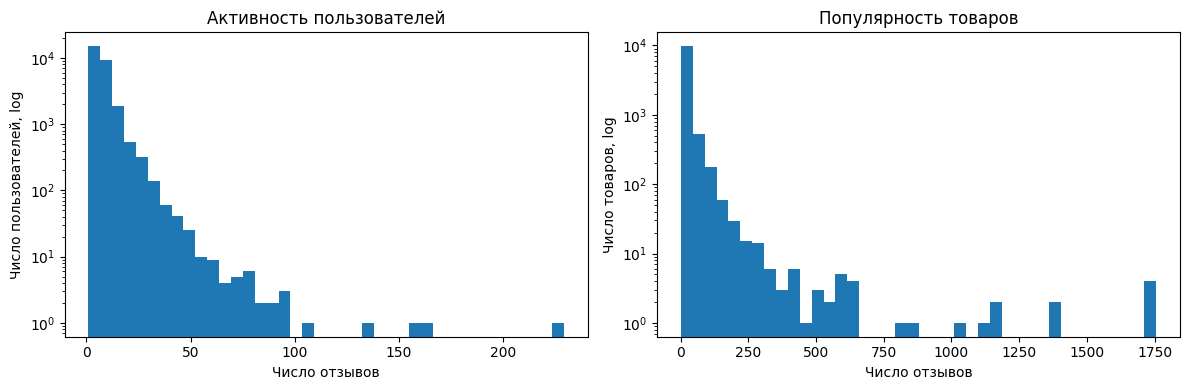

,asin,title,brand,category,reviews
item,,,,,
707,B0002E3CK4,"D'Addario EXL120-7 Nickel Wound 7-String Electric Guitar Strings, Super Light, 9-54",D'Addario,Electric Guitar Strings,1756
1329,B0002H03YY,"D'Addario EXL120+ Nickel Wound Electric Guitar Strings, Super Light Plus, 9.5-44",D'Addario,Electric Guitar Strings,1756
1331,B0002H05BA,"D'Addario EJ21 Nickel Wound Electric Guitar Strings, Jazz Light, 12-52",D'Addario,Electric Guitar Strings,1756
1721,B0006LOBA8,"D'Addario EXL150H Nickel Wound Electric Guitar Strings, High-Strung/Nashville Tuning, 10-26",D'Addario,Electric Guitar Strings,1756
583,B0002E1NNC,"Elixir Strings 80/20 Bronze Acoustic Guitar Strings w POLYWEB Coating, Extra Light (.010-.047)",Elixir,Acoustic Guitar Strings,1370
588,B0002E1NWI,"Elixir Strings 80/20 Bronze Acoustic Guitar Strings w POLYWEB Coating, Light/Medium (.012-.056)",Elixir,Acoustic Guitar Strings,1370
1340,B0002H0A3S,"D'Addario EJ26 Phosphor Bronze Acoustic Guitar Strings, Custom Light, 11-52",D'Addario,Acoustic Guitar Strings,1169
1868,B0007Y09VO,"D'Addario EJ17-B25 Phosphor Bronze Acoustic Guitar Strings, Medium, 13-56, 25 Bulk Sets",D'Addario,Acoustic Guitar Strings,1169
569,B0002E1G5C,"DAddario Accessories Pro-Winder Guitar String Winder and Cutter All-In-1 Restringing Tool Includes Clippers, Bridg...",D'Addario Accessories,Tools,1104


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(user_activity, bins=40, log=True)
axes[0].set(title="Активность пользователей", xlabel="Число отзывов", ylabel="Число пользователей, log")
axes[1].hist(item_popularity, bins=40, log=True)
axes[1].set(title="Популярность товаров", xlabel="Число отзывов", ylabel="Число товаров, log")
plt.tight_layout()
plt.show()

top_items = item_popularity.nlargest(10).rename("reviews").to_frame().join(items)
display(top_items[["asin", "title", "brand", "category", "reviews"]])

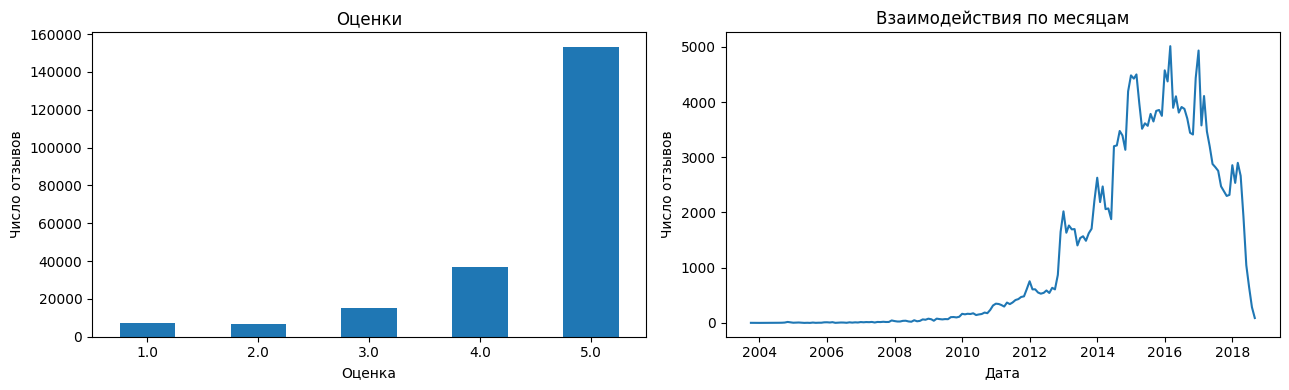

Период: 2003-10-28 00:00:00+00:00 — 2018-09-28 00:00:00+00:00


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
data.rating.value_counts().sort_index().plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Оценки", xlabel="Оценка", ylabel="Число отзывов")
monthly = data.set_index("timestamp").resample("MS").size()
axes[1].plot(monthly.index, monthly.values)
axes[1].set(title="Взаимодействия по месяцам", xlabel="Дата", ylabel="Число отзывов")
plt.tight_layout()
plt.show()
print("Период:", data.timestamp.min(), "—", data.timestamp.max())

,missing_fraction,unique_nonempty
title,0.000847,10577
brand,0.008945,1716
category,0.027307,407


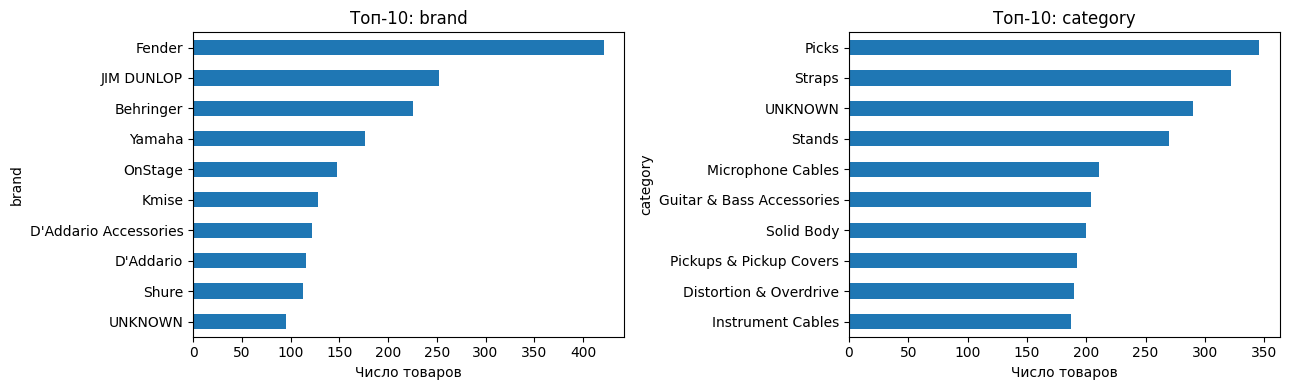

In [8]:
metadata_coverage = pd.DataFrame({
    "missing_fraction": items[["title", "brand", "category"]].eq("").mean(),
    "unique_nonempty": items[["title", "brand", "category"]].replace("", np.nan).nunique(),
})
display(metadata_coverage)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for field, axis in zip(["brand", "category"], axes):
    items[field].replace("", "UNKNOWN").value_counts().head(10).sort_values().plot.barh(ax=axis)
    axis.set(title=f"Топ-10: {field}", xlabel="Число товаров")
plt.tight_layout()
plt.show()

**Подготовка.** Сохраняем первое взаимодействие каждой пары пользователь–товар.
Низкие оценки остаются отрицательным сигналом для iALS и FM; ItemKNN и EASE используют оценки 4–5.
Товары без метаданных не удаляем: FM получает unknown-коды. Матрицы храним в CSR.
Дополнительную подвыборку не формируем.

После удаления 12 236 повторов (5,29%) осталось **219 156 взаимодействий,
27 530 пользователей и 10 620 товаров**. Пропусков в основных полях и некорректных оценок нет.
Разреженность — **99,925%**, медиана истории пользователя — 6 товаров, медиана популярности — 9 отзывов.
На 1% популярных товаров приходится 20,42% взаимодействий; 86,72% оценок положительные.

Бренд отсутствует примерно у 0,89% товаров, категория — у 2,73%. Считаем их постоянными
признаками; цену, sales rank, also-bought и тексты отзывов не используем.
Исходный 5-core отобран авторами по всему периоду; после дедупликации некоторые степени меньше пяти.

## 3. Протокол оценки — фиксируем до подбора

- Общие временные границы: примерно 80% / 10% / 10% взаимодействий; одинаковые даты не разделяются.
- Validation: обучение на train. Финальный test: обучение заново на train + validation.
- Кандидаты: **все товары из текущей обучающей истории**, без семплирования каталога.
- Исключаем все ранее оценённые товары пользователя, независимо от оценки.
- Основной эксперимент — на известных пользователях и товарах. Cold start отдельно считаем ниже.
- Для пользователя нужен хотя бы один релевантный доступный товар и минимум 10 оставшихся кандидатов.
- Пользователи, кандидаты и правила для всех моделей одинаковы. Обучающие таргеты могут различаться,
  но релевантность всегда равна `rating >= 4`.

**Основная метрика — NDCG@10:** учитывает, насколько высоко стоят релевантные товары.
**Вторая — Recall@10:** доля найденных релевантных товаров среди доступных релевантных в будущем периоде.
Обе метрики усредняются по пользователям, а не по взаимодействиям.

$$DCG@10 = \sum_{j=1}^{10}\frac{rel_j}{\log_2(j+1)},\quad
NDCG@10 = \frac{DCG@10}{IDCG@10},\quad
Recall@10 = \frac{|Rec_{10}(u)\cap R_u|}{|R_u|}.$$

Пользователи без доступных релевантных товаров исключаются из обеих метрик. Ненаблюдаемый товар
не обязательно плохой, но в offline-оценке за него нельзя получить положительное попадание.
Параметры выбираем только по validation; test не используем для исправления настроек.

**Охват.** Train заканчивается 27.02.2017, validation — 01.10.2017;
test охватывает 02.10.2017–28.09.2018. Оценены **5 739 из 7 253 пользователей** test-периода.
Исключены 20,87% пользователей из-за отсутствия обучающей истории или доступных релевантных товаров.
В оценку вошли 13 713 из 18 660 положительных test-взаимодействий (73,49%);
каталог содержит 10 599 товаров. Результаты относятся к известным пользователям и товарам.


In [9]:
train, valid, test = temporal_split(data)
split_summary = []
for name, part in [("train", train), ("validation", valid), ("test", test)]:
    split_summary.append({
        "split": name, "interactions": len(part), "users": part.user.nunique(),
        "items": part.item.nunique(), "positive_interactions": int((part.rating >= 4).sum()),
        "start": part.timestamp.min(), "end": part.timestamp.max(),
    })
display(pd.DataFrame(split_summary).set_index("split"))
assert train.timestamp.max() < valid.timestamp.min()
assert valid.timestamp.max() < test.timestamp.min()

train_valid = pd.concat([train, valid], ignore_index=True)

,interactions,users,items,positive_interactions,start,end
split,,,,,,
train,175360,25436,10521,152355,2003-10-28 00:00:00+00:00,2017-02-27 00:00:00+00:00
validation,21904,7531,6109,19028,2017-02-28 00:00:00+00:00,2017-10-01 00:00:00+00:00
test,21892,7253,5874,18660,2017-10-02 00:00:00+00:00,2018-09-28 00:00:00+00:00


In [10]:
coverage = []
for name, history, future in [("validation", train, valid), ("test", train_valid, test)]:
    seen, candidates, truth = prepare_evaluation(history, future, shape)
    cold_users = ~future.user.isin(history.user.unique())
    cold_items = ~future.item.isin(candidates)
    coverage.append({
        "split": name,
        "future_users": future.user.nunique(),
        "evaluated_users": len(truth),
        "excluded_users": future.user.nunique() - len(truth),
        "cold_user_interactions": int(cold_users.sum()),
        "cold_item_interactions": int(cold_items.sum()),
        "positive_interactions": int((future.rating >= 4).sum()),
        "evaluated_positive_pairs": sum(len(values) for values in truth.values()),
        "catalog_size": len(candidates),
    })
display(pd.DataFrame(coverage).set_index("split"))

# Один и тот же обучающий словарь метаданных для всех validation-экспериментов.
item_features = make_item_features(items, train, shape[0])
print("FM: item ID, brand, category; shape =", item_features.shape)

,future_users,evaluated_users,excluded_users,cold_user_interactions,cold_item_interactions,positive_interactions,evaluated_positive_pairs,catalog_size
split,,,,,,,,
validation,7531,5646,1885,6399,234,19028,13184,10521
test,7253,5739,1514,5530,112,18660,13713,10599


FM: item ID, brand, category; shape = (10620, 3)


## 4. Модели и формулы

### ItemKNN

Пусть $X_{ui}=1[r_{ui}\geq4]$, а $x_i$ — столбец товара.
$$s_{ij}=\frac{x_i^\top x_j}{\|x_i\|\|x_j\|+shrink},\quad
score(u,i)=\sum_j X_{uj}S_{ji}.$$
Диагональ $S$ обнуляем; в каждой строке сохраняем $k$ ближайших соседей.
Таким образом каждый товар истории голосует за свои похожие товары.

### iALS

$$\min_{U,V}\sum_{u,i}c_{ui}(p_{ui}-U_u^\top V_i)^2
+\lambda(\|U\|_F^2+\|V\|_F^2).$$
Таргет $p_{ui}=1[r_{ui}\geq4]$ для наблюдаемой пары и 0 иначе.
Confidence $c_{ui}=1+\alpha$ для **любой наблюдаемой пары**, включая низкие оценки,
и 1 для ненаблюдаемой. Отличаем известную низкую оценку от отсутствия данных.
Чередуем аналитические обновления:
$$U_u=(V^\top C_uV+\lambda I)^{-1}V^\top C_up_u.$$
В коде решаем систему, не вычисляя обратную матрицу. Обновление $V$ симметрично.

### EASE

$$\min_B \|X-XB\|_F^2+\lambda\|B\|_F^2,\quad diag(B)=0.$$
$$P=(X^\top X+\lambda I)^{-1},\quad B_{ij}=-P_{ij}/P_{jj},\quad B_{ii}=0.$$
Предсказания: $XB$. Здесь нужна плотная матрица размера $I\times I$.

### FM с метаданными

Вектор признаков содержит четыре категориальных поля: **user ID, item ID, бренд, категория**.
Бренд отражает предпочтение производителя, категория — тип инструмента или аксессуара.
Словари категорий строятся по обучающим товарам; пропуски получают отдельный код.

$$\hat y(x)=w_0+\sum_jw_jx_j+\frac12\sum_f
\left[\left(\sum_jv_{jf}x_j\right)^2-\sum_jv_{jf}^2x_j^2\right].$$
Оптимизируем binary cross-entropy с L2-регуляризацией через Adam.
Наблюдаемые оценки 4–5 имеют label 1, оценки 1–3 — label 0.
На каждый положительный обучающий пример добавляем два случайных ненаблюдаемых товара
того же пользователя с label 0. Из семплирования исключаем **только обучающую историю**,
не заглядывая в validation/test. Отрицательные пары пересемплируются каждую эпоху.
Сравнение с FM только на ID помогает оценить вклад метаданных.

При ранжировании используем score до sigmoid: монотонное преобразование не меняет порядок.
Кешируем часть FM, зависящую только от товара; результат совпадает с исходной FM-формулой.

### iALS с собственным таргетом

Гипотеза: высокая недавняя оценка сильнее отражает текущий интерес.

$$p^{custom}_{ui}=1[r_{ui}\geq4]\cdot\frac{r_{ui}-3}{2}
\cdot 2^{-(T-t_{ui})/H}.$$

$T$ — максимальная дата **в текущей обучающей истории**, $H$ — период полураспада в днях.
Для ненаблюдаемых пар таргет 0. Оценка 4 получает половину силы оценки 5 до затухания.
Изменяется именно целевая матрица $p$, а confidence и ALS-обновления остаются теми же.
У базовой и собственной версии одинаковая сетка факторов и регуляризации; $\alpha=20$ у обеих.
Общий test-критерий релевантности остаётся бинарным: оценка 4–5.

В классе также есть `use_rating=False` и `half_life_days=None` для изучения компонентов
таргета. При отключении обоих компонентов получается в точности базовый iALS.
Popularity — дополнительный baseline: число положительных обучающих отзывов товара.

## 5. Подбор на validation

Небольшие сетки выбраны заранее. Для iALS рассматриваем 32/64 фактора и регуляризацию 0.1/1.0,
для custom iALS добавляем полураспад 365/1095 дней. У обеих версий 10 ALS-итераций и alpha=20.
В FM перебираем 16/32 фактора; остальные настройки фиксированы, одинаковые для FM с метаданными и без.
ItemKNN: 50/100 соседей и shrink 0/10. EASE: регуляризация 100/1000.
Это небольшой стартовый поиск, а не доказательство оптимальности каждой модели.

Все испытания выполняются последовательно, чтобы не держать несколько EASE в памяти.
При одинаковом NDCG выбирается первая конфигурация в списке. После validation настройки фиксируются.

In [11]:
als_configs = [
    {"factors": factors, "reg": reg, "alpha": 20.0, "iterations": 10, "seed": SEED}
    for factors in [32, 64] for reg in [0.1, 1.0]
]
fm_configs = [
    {"factors": factors, "lr": 0.005, "reg": 1e-5, "epochs": 5,
     "batch_size": 2048, "negative_ratio": 2, "device": DEVICE, "seed": SEED}
    for factors in [16, 32]
]

specs = {
    "Popularity": (Popularity, [{}]),
    "ItemKNN": (ItemKNN, [{"k": k, "shrink": shrink} for k in [50, 100] for shrink in [0.0, 10.0]]),
    "iALS": (IALS, als_configs),
    "EASE": (EASE, [{"reg": reg} for reg in [100.0, 1000.0]]),
    "FM": (FM, [{**params, "use_metadata": True} for params in fm_configs]),
    "custom iALS": (CustomIALS, [
        {**params, "use_rating": True, "half_life_days": days}
        for params in als_configs for days in [365, 1095]
    ]),
    "FM IDs": (FM, [{**params, "use_metadata": False} for params in fm_configs]),
}
display(pd.Series({name: len(configs) for name, (_, configs) in specs.items()}, name="trials"))

Popularity     1
ItemKNN        4
iALS           4
EASE           2
FM             2
custom iALS    8
FM IDs         2
Name: trials, dtype: int64

In [12]:
validation_results, best_params = tune_models(specs, train, valid, shape, item_features)
display(validation_results.sort_values(["model", "NDCG@10"], ascending=[True, False]))
display(pd.Series(best_params, name="chosen_parameters"))

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
validation_results.to_csv(RESULTS_DIR / "validation.csv", index=False)
with (RESULTS_DIR / "config.json").open("w", encoding="utf-8") as file:
    json.dump({
        "seed": SEED, "threads": N_THREADS, "source": SOURCE,
        "shape": shape, "interactions": len(data),
        "train_end": str(train.timestamp.max()), "valid_end": str(valid.timestamp.max()),
        "search_spaces": {name: configs for name, (_, configs) in specs.items()},
        "best_params": best_params,
        "versions": {name: version(name) for name in ["numpy", "scipy", "pandas", "torch", "matplotlib"]},
    }, file, ensure_ascii=False, indent=2)

Popularity: {}


ItemKNN: {'k': 50, 'shrink': 0.0}


ItemKNN: {'k': 50, 'shrink': 10.0}


ItemKNN: {'k': 100, 'shrink': 0.0}


ItemKNN: {'k': 100, 'shrink': 10.0}


...

custom iALS: {'factors': 64, 'reg': 1.0, 'alpha': 20.0, 'iterations': 10, 'seed': 42, 'use_rating': True, 'half_life_days': 1095}


FM IDs: {'factors': 16, 'lr': 0.005, 'reg': 1e-05, 'epochs': 5, 'batch_size': 2048, 'negative_ratio': 2, 'device': 'cpu', 'seed': 42, 'use_metadata': False}


FM IDs: {'factors': 32, 'lr': 0.005, 'reg': 1e-05, 'epochs': 5, 'batch_size': 2048, 'negative_ratio': 2, 'device': 'cpu', 'seed': 42, 'use_metadata': False}


,model,params,NDCG@10,Recall@10,fit_seconds,eval_seconds
10,EASE,"{""reg"": 1000.0}",0.019831,0.032423,47.140026,5.577789
9,EASE,"{""reg"": 100.0}",0.018008,0.029601,47.128842,5.574029
11,FM,"{""factors"": 16, ""lr"": 0.005, ""reg"": 1e-05, ""epochs"": 5, ""batch_size"": 2048, ""negative_ratio"": 2, ""device"": ""cpu"", ""s...",0.017095,0.025462,6.308848,5.377747
12,FM,"{""factors"": 32, ""lr"": 0.005, ""reg"": 1e-05, ""epochs"": 5, ""batch_size"": 2048, ""negative_ratio"": 2, ""device"": ""cpu"", ""s...",0.016071,0.023712,7.425799,5.292787
21,FM IDs,"{""factors"": 16, ""lr"": 0.005, ""reg"": 1e-05, ""epochs"": 5, ""batch_size"": 2048, ""negative_ratio"": 2, ""device"": ""cpu"", ""s...",0.017127,0.024531,4.487423,5.272737
22,FM IDs,"{""factors"": 32, ""lr"": 0.005, ""reg"": 1e-05, ""epochs"": 5, ""batch_size"": 2048, ""negative_ratio"": 2, ""device"": ""cpu"", ""s...",0.016851,0.024528,5.922718,5.293933
4,ItemKNN,"{""k"": 100, ""shrink"": 10.0}",0.016185,0.024764,0.178466,1.723559
2,ItemKNN,"{""k"": 50, ""shrink"": 10.0}",0.015592,0.024227,0.194102,1.492600
3,ItemKNN,"{""k"": 100, ""shrink"": 0.0}",0.008846,0.013443,0.177498,1.729889
1,ItemKNN,"{""k"": 50, ""shrink"": 0.0}",0.008511,0.012631,0.196242,1.495225


Popularity                                                                                                                          {}
ItemKNN                                                                                                     {'k': 100, 'shrink': 10.0}
iALS                                                          {'factors': 64, 'reg': 0.1, 'alpha': 20.0, 'iterations': 10, 'seed': 42}
EASE                                                                                                                   {'reg': 1000.0}
FM             {'factors': 16, 'lr': 0.005, 'reg': 1e-05, 'epochs': 5, 'batch_size': 2048, 'negative_ratio': 2, 'device': 'cpu', 's...
custom iALS       {'factors': 32, 'reg': 0.1, 'alpha': 20.0, 'iterations': 10, 'seed': 42, 'use_rating': True, 'half_life_days': 1095}
FM IDs         {'factors': 16, 'lr': 0.005, 'reg': 1e-05, 'epochs': 5, 'batch_size': 2048, 'negative_ratio': 2, 'device': 'cpu', 's...
Name: chosen_parameters, dtype: object

## 6. Финальный test

Переобучаем выбранные конфигурации с нуля на train + validation. Словарь метаданных теперь также
использует train + validation; кандидаты — товары, известные к началу test. Все модели получают
один набор тестовых пользователей. Test применяется только для этой финальной таблицы.
Время оценки включает all-item scoring, маскирование, ранжирование и подсчёт метрик.

In [13]:
final_item_features = make_item_features(items, train_valid, shape[0])
test_results, per_user_results = final_comparison(
    specs, best_params, train_valid, test, shape, final_item_features
)
display(test_results.reset_index(drop=True))
test_results.to_csv(RESULTS_DIR / "test.csv", index=False)
pd.concat(per_user_results, names=["model", "user"]).to_csv(RESULTS_DIR / "test_per_user.csv")

Финальное обучение: Popularity


Финальное обучение: ItemKNN


Финальное обучение: iALS


Финальное обучение: EASE


Финальное обучение: FM


Финальное обучение: custom iALS


Финальное обучение: FM IDs


,model,params,NDCG@10,Recall@10,fit_seconds,eval_seconds
0,Popularity,{},0.019468,0.024738,0.023253,3.539716
1,FM,"{""factors"": 16, ""lr"": 0.005, ""reg"": 1e-05, ""epochs"": 5, ""batch_size"": 2048, ""negative_ratio"": 2, ""device"": ""cpu"", ""s...",0.019000,0.025212,6.408396,5.390837
2,custom iALS,"{""factors"": 32, ""reg"": 0.1, ""alpha"": 20.0, ""iterations"": 10, ""seed"": 42, ""use_rating"": true, ""half_life_days"": 1095}",0.017927,0.028931,30.133237,5.428420
3,iALS,"{""factors"": 64, ""reg"": 0.1, ""alpha"": 20.0, ""iterations"": 10, ""seed"": 42}",0.015782,0.026349,55.358362,5.506214
4,EASE,"{""reg"": 1000.0}",0.015257,0.024934,47.071710,5.694432
5,FM IDs,"{""factors"": 16, ""lr"": 0.005, ""reg"": 1e-05, ""epochs"": 5, ""batch_size"": 2048, ""negative_ratio"": 2, ""device"": ""cpu"", ""s...",0.013096,0.020693,5.034093,5.383757
6,ItemKNN,"{""k"": 100, ""shrink"": 10.0}",0.011844,0.018093,0.187890,1.566861


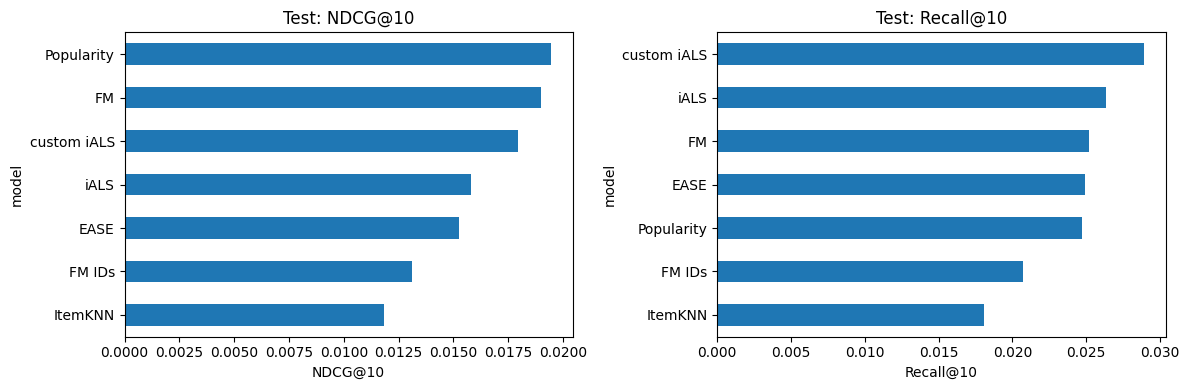

Лучший NDCG@10: Popularity


,FM minus FM IDs,custom iALS minus iALS
NDCG@10,0.005903,0.002145
Recall@10,0.004519,0.002581


In [14]:
table = test_results.set_index("model")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for metric, axis in zip(["NDCG@10", "Recall@10"], axes):
    table[metric].sort_values().plot.barh(ax=axis)
    axis.set(title=f"Test: {metric}", xlabel=metric)
plt.tight_layout()
plt.show()

print("Лучший NDCG@10:", table["NDCG@10"].idxmax())
display(pd.DataFrame({
    "FM minus FM IDs": table.loc["FM", ["NDCG@10", "Recall@10"]] - table.loc["FM IDs", ["NDCG@10", "Recall@10"]],
    "custom iALS minus iALS": table.loc["custom iALS", ["NDCG@10", "Recall@10"]] - table.loc["iALS", ["NDCG@10", "Recall@10"]],
}))

## 7. Выводы

На test получены следующие результаты. Настройки выбраны только по validation.

| Модель | NDCG@10 | Recall@10 | Выбранные настройки |
|---|---:|---:|---|
| Popularity | **0,019468** | 0,024738 | — |
| FM с метаданными | 0,019000 | 0,025212 | 16 факторов, lr=0,005, L2=0,00001 |
| custom iALS | 0,017927 | **0,028931** | 32 фактора, reg=0,1, H=1095 дней |
| iALS | 0,015782 | 0,026349 | 64 фактора, reg=0,1 |
| EASE | 0,015257 | 0,024934 | reg=1000 |
| FM только с ID | 0,013096 | 0,020693 | 16 факторов, lr=0,005, L2=0,00001 |
| ItemKNN | 0,011844 | 0,018093 | k=100, shrink=10 |

У обеих версий iALS alpha=20 и 10 итераций. Обе FM обучались 5 эпох с batch size 2048
и двумя дополнительными отрицательными примерами на положительный. Seed=42.

**Лидеры.** По основной метрике NDCG@10 победил Popularity. Среди пяти обязательных моделей
лучшей стала FM с метаданными: её NDCG ниже Popularity примерно на 2,4%, а Recall выше на 1,9%.
По Recall@10 лидирует custom iALS, превосходящий Popularity примерно на 16,9%.
Модели не превзошли простой baseline по основной метрике; короткие истории и высокая
концентрация популярности могут затруднять персонализацию, но причина отдельно не проверялась.

**Метаданные.** На test FM с брендом и категорией улучшила NDCG относительно FM только с ID
примерно на **45,1%**, Recall — на **21,8%**. Однако на validation её NDCG был чуть ниже:
0,017095 против 0,017127. Устойчивость эффекта на других периодах и seed не установлена.

**Собственный таргет.** custom iALS улучшил test NDCG базового iALS примерно на **13,6%**,
Recall — на **9,8%**. При равных настройках на validation (32 фактора, reg=0,1)
NDCG вырос с 0,018666 до 0,020102. Полураспад 1095 дней оказался лучше 365 во всех
четырёх парах общих настроек. На test лучшие версии имеют разное число факторов,
поэтому всю разницу нельзя приписать только таргету; вклад оценки и давности отдельно не измерялся.

**Настройки и затраты.** При k=100 shrink повысил validation NDCG ItemKNN с 0,008846 до 0,016185;
у EASE reg=1000 дал 0,019831 против 0,018008 при reg=100. Тем не менее на test ItemKNN
оказался последним, а EASE уступил Popularity и обеим версиям iALS. FM обучилась за 6,41 с,
custom iALS — за 30,13 с, iALS — за 55,36 с, EASE — за 47,07 с.
Смена лидера с custom iALS на validation на Popularity на test показывает зависимость
результатов от временного периода и состава пользователей.

**Ограничения.** Использованы ретроспективный 5-core, один временной split и seed,
небольшие сетки параметров. Оценка исключает 20,87% пользователей и 26,51% положительных
взаимодействий будущего периода. Нет показов, достоверных негативов и исторических метаданных.
Статистическая значимость различий не проверялась.

В текущей FM отрицательные примеры выбираются из всех ID, включая 99 товаров вне
обучающего каталога при validation и 21 при финальном обучении. Отложенные оценки
не используются, но для строгого временного протокола следует ограничить отрицательные
примеры текущим обучающим каталогом и повторить обе FM. Влияние этого несоответствия
не измерено; приведённые результаты относятся к исходной реализации.